# Olist — EDA and dashboard decisions

**Audience:** one e-commerce fulfillment operations manager.
**Decision:** prioritize overdue open orders and assign seller or carrier follow-up.

Source: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce),
anonymized real commercial orders, 2016–2018. This notebook analyzes the one-order-per-row
CSV prepared by `scripts/prepare_olist.py`. That script first aggregates item prices at
order level, then joins customers with cardinality checks. No sampling is performed.
Re-download the three original files with `scripts/download_olist.py` if reconstruction
from the official source is needed; the small derived CSV is already in the repository.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fulfillment import load_orders, replay_cohort, overdue_orders, headline, backlog_trend
%matplotlib inline
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
orders = load_orders('data/olist_orders.csv')
cohort = replay_cohort(orders)
print('Rows and columns:', orders.shape)
print('Derived CSV bytes:', Path('data/olist_orders.csv').stat().st_size)
print('Purchase coverage:', orders.purchase_at.min(), 'to', orders.purchase_at.max())
print('Unique order IDs:', orders.order_id.nunique())
display(orders.head())
display(orders.dtypes.rename('dtype').to_frame())
display(orders.isna().sum().rename('missing').to_frame())
display(orders.describe().T)

Rows and columns: (99441, 11)
Derived CSV bytes: 16045919
Purchase coverage: 2016-09-04 21:15:19 to 2018-10-17 17:30:18
Unique order IDs: 99441


,order_id,purchase_at,approved_at,handoff_at,delivered_at,promised_date,final_status,destination_state,merchandise_brl,item_count,seller_count
0,2e7a8482f6fb09756ca50c10d7bfc047,2016-09-04 21:15:19,2016-10-07 13:18:03,2016-10-18 13:14:51,NaT,2016-10-20,shipped,RR,72.89,2.0,1.0
1,e5fa5a7210941f7d56d0208e4e071d35,2016-09-05 00:15:34,2016-10-07 13:17:15,NaT,NaT,2016-10-28,canceled,RS,59.50,1.0,1.0
2,809a282bbd5dbcabb6f2f724fca862ec,2016-09-13 15:24:19,2016-10-07 13:16:46,NaT,NaT,2016-09-30,canceled,SP,NaN,NaN,NaN
3,bfbd0f9bdef84302105ad712db648a6c,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04,delivered,SP,134.97,3.0,1.0
4,71303d7e93b399f5bcd537d124c0bcfa,2016-10-02 22:07:52,2016-10-06 15:50:56,NaT,NaT,2016-10-25,canceled,SP,100.00,1.0,1.0


,dtype
order_id,object
purchase_at,datetime64[ns]
approved_at,datetime64[ns]
handoff_at,datetime64[ns]
delivered_at,datetime64[ns]
promised_date,datetime64[ns]
final_status,object
destination_state,object
merchandise_brl,float64
item_count,float64


,missing
order_id,0
purchase_at,0
approved_at,160
handoff_at,1783
delivered_at,2965
promised_date,0
final_status,0
destination_state,0
merchandise_brl,775
item_count,775


,count,mean,min,25%,50%,75%,max,std
purchase_at,99441,2017-12-31 08:43:12.776581120,2016-09-04 21:15:19,2017-09-12 14:46:19,2018-01-18 23:04:36,2018-05-04 15:42:16,2018-10-17 17:30:18,NaN
approved_at,99281,2017-12-31 18:35:24.098800384,2016-09-15 12:16:38,2017-09-12 23:24:16,2018-01-19 11:36:13,2018-05-04 20:35:10,2018-09-03 17:40:06,NaN
handoff_at,97658,2018-01-04 21:49:48.138278656,2016-10-08 10:34:01,2017-09-15 22:28:50.249999872,2018-01-24 16:10:58,2018-05-08 13:37:45,2018-09-11 19:48:28,NaN
delivered_at,96476,2018-01-14 12:09:19.035542528,2016-10-11 13:46:32,2017-09-25 22:07:22.249999872,2018-02-02 19:28:10.500000,2018-05-15 22:48:52.249999872,2018-10-17 13:22:46,NaN
promised_date,99441,2018-01-24 03:08:37.730111232,2016-09-30 00:00:00,2017-10-03 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-11-12 00:00:00,NaN
merchandise_brl,98666.0,137.754076,0.85,45.9,86.9,149.9,13440.0,210.645145
item_count,98666.0,1.141731,1.0,1.0,1.0,1.0,21.0,0.538452
seller_count,98666.0,1.013622,1.0,1.0,1.0,1.0,5.0,0.122297


Missing delivery timestamps can describe open orders, so they are not blindly filled or
dropped. Missing approval, promise or merchandise value prevents safe inclusion in this
particular replay. Final cancellation status is known only retrospectively: excluding
cancelled/unavailable orders defines a limited cohort, not a complete reconstruction of
the live historical order book. The dashboard states this limitation explicitly.

,orders
final_canceled_or_unavailable,1234
missing_approval,160
missing_item_value,775
handoff_before_approval,1359
delivery_before_handoff,23
delivery_before_approval,61
delivered_but_missing_handoff,1
excluded_union,2639
replay_cohort,96802


,orders
final_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,orders
purchase_at,
2016-09,4
2016-10,324
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700
2017-06,3245


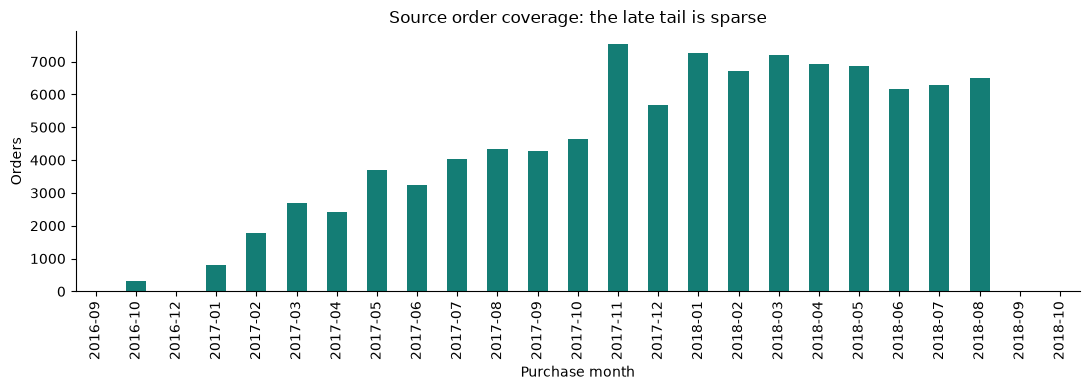

In [2]:
quality = pd.Series({
    'final_canceled_or_unavailable': orders.final_status.isin(['canceled','unavailable']).sum(),
    'missing_approval': orders.approved_at.isna().sum(),
    'missing_item_value': orders.merchandise_brl.isna().sum(),
    'handoff_before_approval': (orders.handoff_at < orders.approved_at).sum(),
    'delivery_before_handoff': (orders.delivered_at < orders.handoff_at).sum(),
    'delivery_before_approval': (orders.delivered_at < orders.approved_at).sum(),
    'delivered_but_missing_handoff': (orders.delivered_at.notna() & orders.handoff_at.isna()).sum(),
    'excluded_union': len(orders) - len(cohort),
    'replay_cohort': len(cohort),
}, name='orders')
display(quality.to_frame())
display(orders.final_status.value_counts().rename('orders').to_frame())
monthly = orders.groupby(orders.purchase_at.dt.to_period('M')).size()
display(monthly.rename('orders').to_frame())
fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot.bar(ax=ax, color='#147D75')
ax.set(title='Source order coverage: the late tail is sparse', xlabel='Purchase month', ylabel='Orders')
fig.tight_layout()
plt.show()

The source's late tail is not evidence of a business collapse: September and October
2018 are sparsely represented. The app therefore restricts the replay date to February
2017–August 2018 and shows the full source period separately. Impossible milestone
sequences are excluded rather than silently re-ordered. Quality counts overlap, so only
the union is used for the total excluded count.

Default historical view: 2018-08-01 00:00:00 {'overdue_orders': 1649, 'merchandise_brl': 262443.3, 'awaiting_handoff': 585}


,orders,merchandise_brl
stage,,
Awaiting seller handoff,585,118377.07
With carrier,1064,144066.23


,orders,merchandise_brl
destination_state,,
SP,600,91601.45
RJ,321,48375.09
MG,135,19663.43
BA,86,13296.10
RS,70,14177.43
PR,56,10258.44
SC,51,11471.95
PE,50,9965.65
CE,42,6325.79


,days_overdue,merchandise_brl
count,1649.000000,1649.000000
mean,247.972711,159.153002
std,155.279504,219.374070
min,1.000000,3.500000
25%,113.000000,48.900000
50%,226.000000,89.990000
75%,380.000000,169.900000
max,650.000000,2492.500000


Orders with multiple sellers in source: 1278


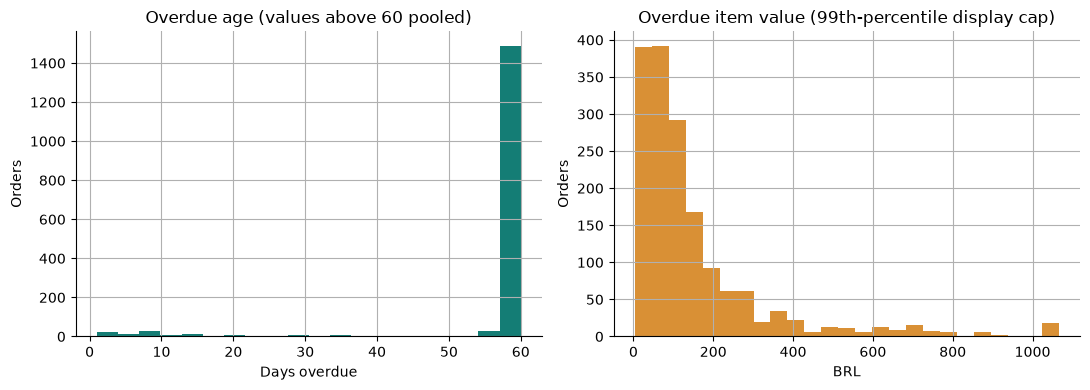

In [3]:
as_of = pd.Timestamp('2018-08-01')
queue = overdue_orders(cohort, as_of)
metrics = headline(queue)
print('Default historical view:', as_of, metrics)
stage = queue.groupby('stage').agg(orders=('order_id','size'), merchandise_brl=('merchandise_brl','sum'))
display(stage)
display(queue.groupby('destination_state').agg(orders=('order_id','size'), merchandise_brl=('merchandise_brl','sum')).sort_values('orders',ascending=False).head(10))
display(queue[['days_overdue','merchandise_brl']].describe())
print('Orders with multiple sellers in source:', int((orders.seller_count > 1).sum()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
queue.days_overdue.clip(upper=60).hist(ax=axes[0], bins=20, color='#147D75')
axes[0].set(title='Overdue age (values above 60 pooled)', xlabel='Days overdue', ylabel='Orders')
queue.merchandise_brl.clip(upper=queue.merchandise_brl.quantile(.99)).hist(ax=axes[1],bins=25,color='#D99035')
axes[1].set(title='Overdue item value (99th-percentile display cap)',xlabel='BRL',ylabel='Orders')
fig.tight_layout()
plt.show()

The queue contains both orders not yet handed to a carrier and orders already with a
carrier. This split identifies different follow-up owners; it earns a place on the app.
The value distribution is skewed, so the app displays total item value alongside count
and keeps individual values in the optional action queue. No values are capped in the
KPIs: the caps above are for EDA visualization only. Long-overdue records may also be
stale source records, so the manager must verify current status before escalating.

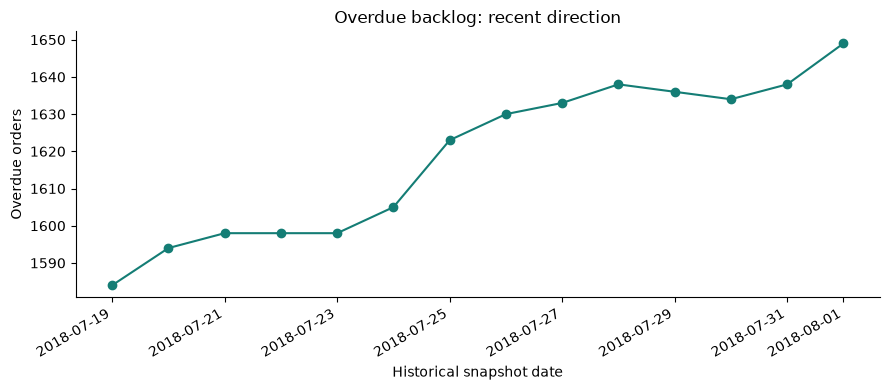

,Date,Overdue orders
0,2018-07-19,1584
1,2018-07-20,1594
2,2018-07-21,1598
3,2018-07-22,1598
4,2018-07-23,1598
5,2018-07-24,1605
6,2018-07-25,1623
7,2018-07-26,1630
8,2018-07-27,1633
9,2018-07-28,1638


In [4]:
trend = backlog_trend(cohort, as_of)
fig, ax = plt.subplots()
ax.plot(trend.Date, trend['Overdue orders'],marker='o',color='#147D75')
ax.set(title='Overdue backlog: recent direction',xlabel='Historical snapshot date',ylabel='Overdue orders')
fig.autofmt_xdate(); fig.tight_layout()
plt.show()
display(trend)

## Decisions carried into the app

- **Top:** overdue open orders, their merchandise value, and the count awaiting seller handoff.
  These answer how large the exception is and whether seller action is still possible.
- **Middle:** one 14-day trend and one stage breakdown. These show direction and follow-up owner.
- **Bottom:** a collapsed queue sorted by overdue days, then item value, with order IDs and export.
  This supports actual case assignment while keeping the first screen small.
- **Filters:** historical review date and delivery destination. A manager can focus a regional review.
- **Cut:** payment-method mix and product-popularity rankings. Neither changes who should follow up
  these already approved overdue orders. A geographic map is also omitted: a destination filter and
  actionable order queue are more useful here and avoid a large geolocation file.
- **Refresh:** hourly in production, reviewed at 09:00 and 15:00; a >20% daily rise from a base of
  at least 20 overdue orders triggers an exception alert. Thresholds are proposed operating rules,
  not statistically calibrated or empirically optimal thresholds.

No predictive model is necessary for this Part 1 decision. The full design justification,
business cost of stale data, metric definitions and production limitations are in `README.md`.